In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path

In [2]:
PROJECT_ROOT = Path("..")

REPORTS_DIR = PROJECT_ROOT / "reports"

FIGURES_DIR = REPORTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Reports:", REPORTS_DIR)
print("Figures:", FIGURES_DIR)

Reports: ../reports
Figures: ../reports/figures


In [3]:
cardio_results = pd.read_csv(REPORTS_DIR / "tabular_model_test_comparison.csv")

print(cardio_results.to_string(index=False))

               model  accuracy  precision   recall       f1  roc_auc   pr_auc
 Logistic Regression  0.731260   0.760401 0.665280 0.709667 0.793824 0.773638
       Random Forest  0.712410   0.710329 0.704947 0.707628 0.766869 0.744146
HistGradientBoosting  0.736688   0.753429 0.693656 0.722308 0.803797 0.784888


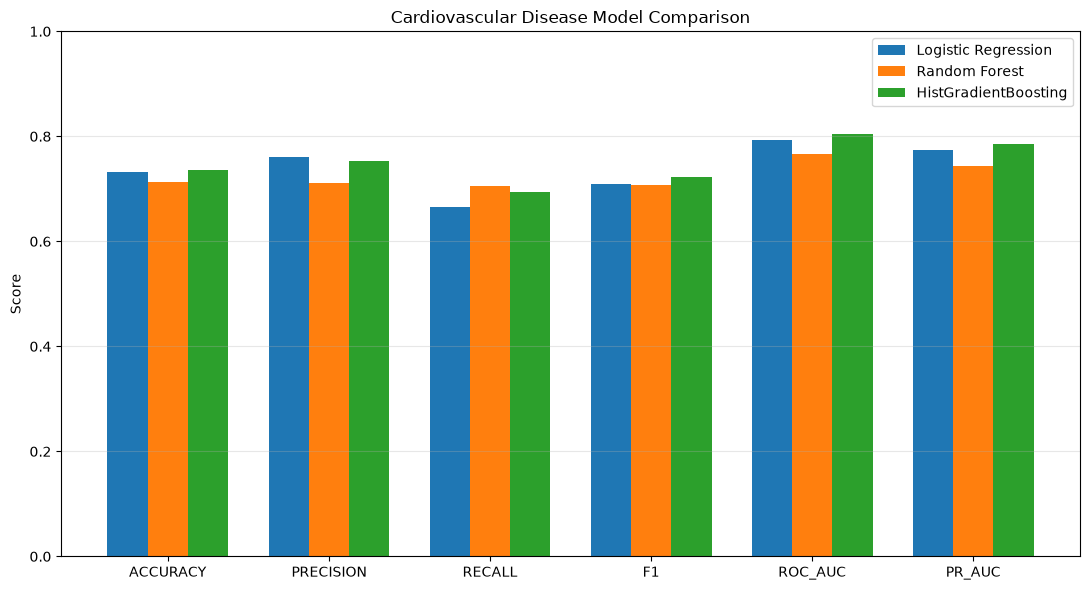

In [4]:
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]

plt.figure(figsize=(11, 6))

x = range(len(cardio_results))

width = 0.25

for i, model in enumerate(cardio_results["model"]):

    values = cardio_results.loc[cardio_results["model"] == model, metrics].iloc[0]

    positions = [j + (i - 1) * width for j in range(len(metrics))]

    plt.bar(positions, values, width=width, label=model)

plt.xticks(range(len(metrics)), [metric.upper() for metric in metrics])

plt.ylabel("Score")

plt.title("Cardiovascular Disease Model Comparison")

plt.ylim(0, 1)

plt.legend()

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cardiovascular_model_comparison.png", dpi=300, bbox_inches="tight"
)

plt.show()

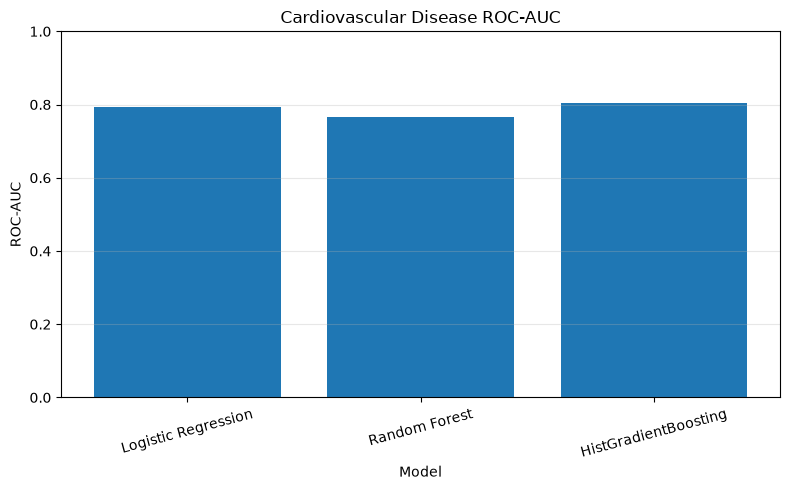

In [5]:
plt.figure(figsize=(8, 5))

plt.bar(cardio_results["model"], cardio_results["roc_auc"])

plt.ylabel("ROC-AUC")

plt.xlabel("Model")

plt.title("Cardiovascular Disease ROC-AUC")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(FIGURES_DIR / "cardiovascular_roc_auc.png", dpi=300, bbox_inches="tight")

plt.show()

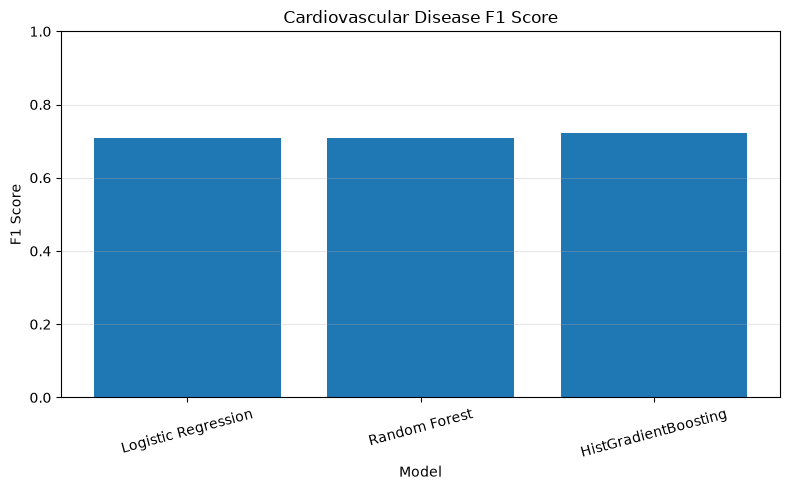

In [6]:
plt.figure(figsize=(8, 5))

plt.bar(cardio_results["model"], cardio_results["f1"])

plt.ylabel("F1 Score")

plt.xlabel("Model")

plt.title("Cardiovascular Disease F1 Score")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(FIGURES_DIR / "cardiovascular_f1.png", dpi=300, bbox_inches="tight")

plt.show()

In [7]:
ptbxl_metrics = pd.read_csv(REPORTS_DIR / "ptbxl_cnn_final_metrics.csv")

print(ptbxl_metrics.to_string(index=False))

                 metric  value
          ROC-AUC Macro 0.9015
          ROC-AUC Micro 0.9185
Average Precision Macro 0.7618
Average Precision Micro 0.8239
               F1 Macro 0.7036
               F1 Micro 0.7489


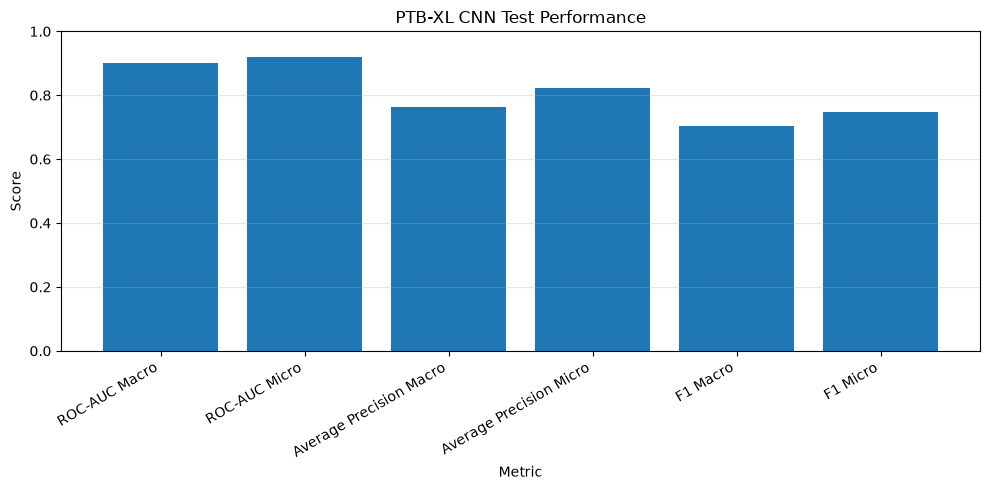

In [8]:
plt.figure(figsize=(10, 5))

plt.bar(ptbxl_metrics["metric"], ptbxl_metrics["value"])

plt.ylabel("Score")

plt.xlabel("Metric")

plt.title("PTB-XL CNN Test Performance")

plt.ylim(0, 1)

plt.xticks(rotation=30, ha="right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(FIGURES_DIR / "ptbxl_cnn_overall_metrics.png", dpi=300, bbox_inches="tight")

plt.show()

In [9]:
ptbxl_class_metrics = pd.read_csv(REPORTS_DIR / "ptbxl_cnn_class_metrics.csv")

print(ptbxl_class_metrics.to_string(index=False))

class  threshold  test_f1
 NORM       0.47   0.8444
   MI       0.21   0.7259
 STTC       0.42   0.7517
   CD       0.45   0.7330
  HYP       0.23   0.4632


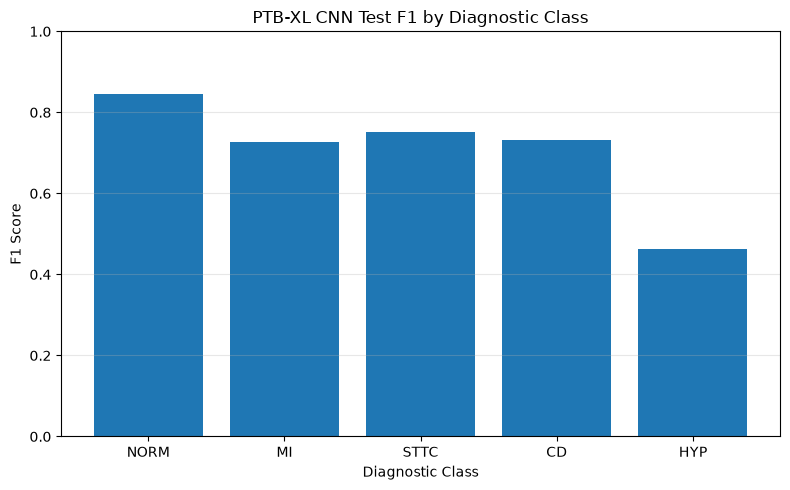

In [10]:
plt.figure(figsize=(8, 5))

plt.bar(ptbxl_class_metrics["class"], ptbxl_class_metrics["test_f1"])

plt.xlabel("Diagnostic Class")

plt.ylabel("F1 Score")

plt.title("PTB-XL CNN Test F1 by Diagnostic Class")

plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(FIGURES_DIR / "ptbxl_class_f1.png", dpi=300, bbox_inches="tight")

plt.show()

In [11]:
threshold_results = pd.read_csv(REPORTS_DIR / "ptbxl_threshold_comparison.csv")

print(threshold_results.to_string(index=False))

                     approach  test_macro_f1
        Fixed threshold = 0.5         0.6470
Validation-derived thresholds         0.7036


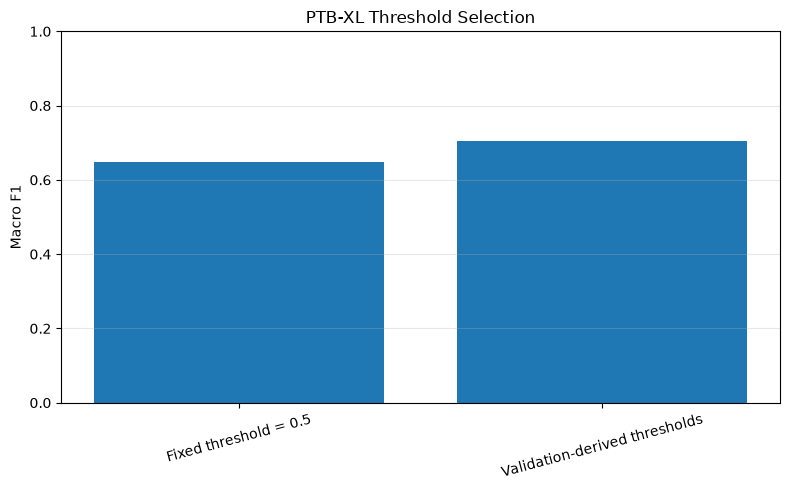

In [12]:
plt.figure(figsize=(8, 5))

plt.bar(threshold_results["approach"], threshold_results["test_macro_f1"])

plt.ylabel("Macro F1")

plt.title("PTB-XL Threshold Selection")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "ptbxl_threshold_comparison.png", dpi=300, bbox_inches="tight"
)

plt.show()

In [13]:
lead_importance_path = REPORTS_DIR / "interpretation" / "ptbxl_cnn_lead_importance.csv"

lead_importance = pd.read_csv(lead_importance_path)

print(lead_importance.head())

print("\nColumns:")

print(lead_importance.columns.tolist())

  class lead  importance
0  NORM    I    0.137981
1  NORM   II    0.122164
2  NORM  III    0.080598
3  NORM  aVR    0.151545
4  NORM  aVL    0.079329

Columns:
['class', 'lead', 'importance']


In [14]:
print(lead_importance.to_string(index=False))

class lead  importance
 NORM    I    0.137981
 NORM   II    0.122164
 NORM  III    0.080598
 NORM  aVR    0.151545
 NORM  aVL    0.079329
 NORM  aVF    0.105580
 NORM   V1    0.145130
 NORM   V2    0.120566
 NORM   V3    0.093238
 NORM   V4    0.086872
 NORM   V5    0.099761
 NORM   V6    0.125903
   MI    I    0.038742
   MI   II    0.038051
   MI  III    0.032186
   MI  aVR    0.051962
   MI  aVL    0.026729
   MI  aVF    0.055952
   MI   V1    0.062931
   MI   V2    0.067743
   MI   V3    0.040148
   MI   V4    0.039401
   MI   V5    0.031061
   MI   V6    0.041384
 STTC    I    0.151982
 STTC   II    0.139704
 STTC  III    0.089462
 STTC  aVR    0.187014
 STTC  aVL    0.100096
 STTC  aVF    0.122522
 STTC   V1    0.167121
 STTC   V2    0.146921
 STTC   V3    0.128591
 STTC   V4    0.113517
 STTC   V5    0.132722
 STTC   V6    0.162054
   CD    I    0.068185
   CD   II    0.060795
   CD  III    0.036320
   CD  aVR    0.072299
   CD  aVL    0.044756
   CD  aVF    0.043546
   CD   V1 

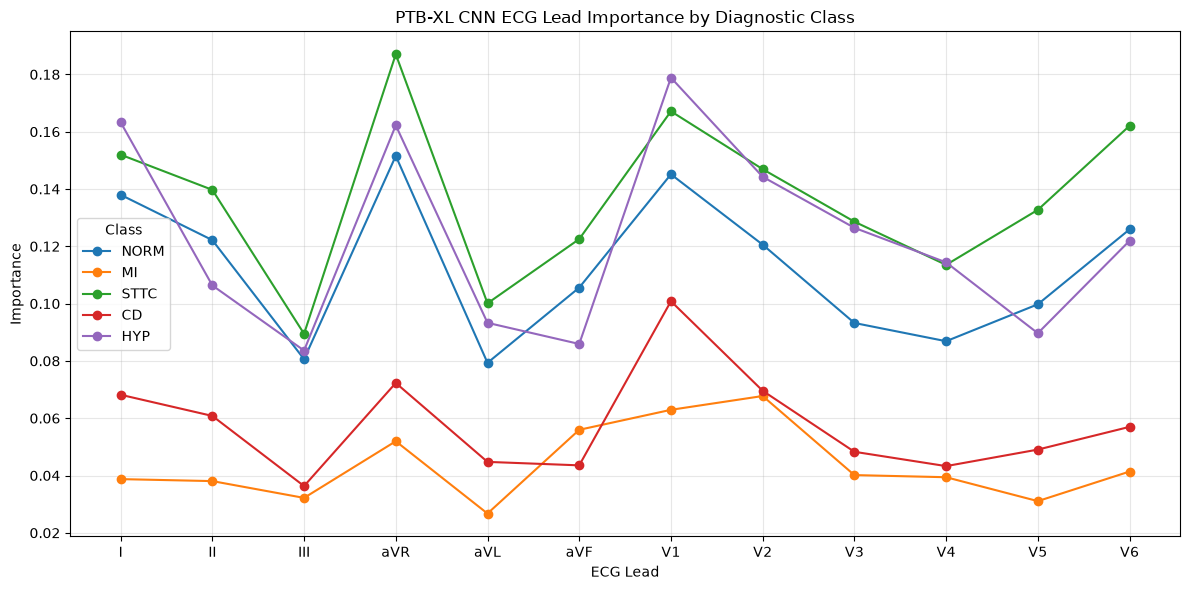

In [15]:
plt.figure(figsize=(12, 6))

for diagnostic_class in lead_importance["class"].unique():

    subset = lead_importance[lead_importance["class"] == diagnostic_class]

    plt.plot(subset["lead"], subset["importance"], marker="o", label=diagnostic_class)

plt.xlabel("ECG Lead")

plt.ylabel("Importance")

plt.title("PTB-XL CNN ECG Lead Importance by Diagnostic Class")

plt.legend(title="Class")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(FIGURES_DIR / "ptbxl_lead_importance.png", dpi=300, bbox_inches="tight")

plt.show()

In [21]:
interpretation_summary_path = (
    REPORTS_DIR / "interpretation" / "ptbxl_cnn_interpretation_summary.csv"
)

interpretation_summary = pd.read_csv(interpretation_summary_path)

print("Columns:")
print(interpretation_summary.columns.tolist())

print("\nShape:")
print(interpretation_summary.shape)

print("\nData:")
print(interpretation_summary.to_string(index=False))

Columns:
['class', 'top_lead', 'top_lead_importance']

Shape:
(5, 3)

Data:
class top_lead  top_lead_importance
 NORM      aVR             0.151545
   MI       V2             0.067743
 STTC      aVR             0.187014
   CD       V1             0.100835
  HYP       V1             0.178855


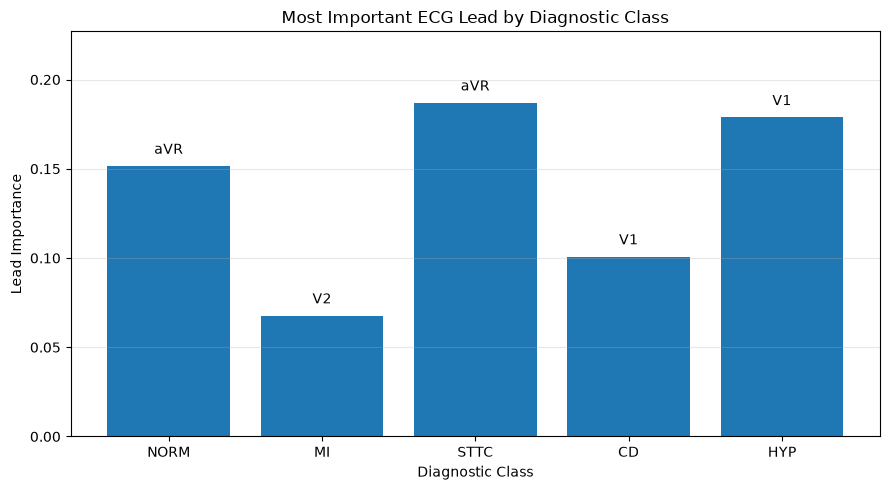

In [23]:
plt.figure(figsize=(9, 5))

plt.bar(interpretation_summary["class"], interpretation_summary["top_lead_importance"])

# Add the lead name above each bar
for i, row in interpretation_summary.iterrows():
    plt.text(
        i, row["top_lead_importance"] + 0.005, row["top_lead"], ha="center", va="bottom"
    )

plt.xlabel("Diagnostic Class")

plt.ylabel("Lead Importance")

plt.title("Most Important ECG Lead by Diagnostic Class")

plt.ylim(0, interpretation_summary["top_lead_importance"].max() + 0.04)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(FIGURES_DIR / "ptbxl_top_leads_by_class.png", dpi=300, bbox_inches="tight")

plt.show()

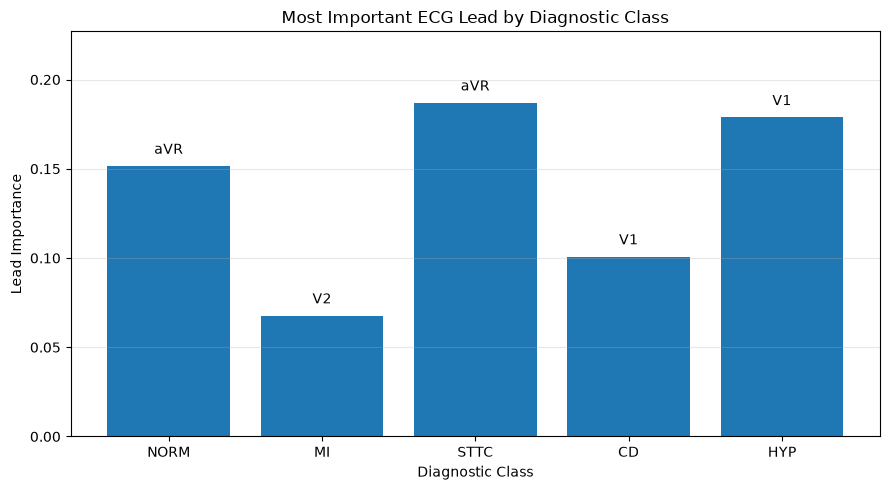

In [ ]:
print("Generated figures:")

for path in sorted(FIGURES_DIR.glob("*.png")):

    print(path.name)

In [24]:
print("=" * 70)
print("NOTEBOOK 14 — GENERATED FIGURES")
print("=" * 70)

figure_files = sorted(FIGURES_DIR.glob("*.png"))

for i, path in enumerate(figure_files, start=1):
    print(f"{i:02d}. {path.name}")

print(f"\nTotal figures: {len(figure_files)}")

NOTEBOOK 14 — GENERATED FIGURES
01. cardiovascular_f1.png
02. cardiovascular_model_comparison.png
03. cardiovascular_roc_auc.png
04. ptbxl_class_f1.png
05. ptbxl_cnn_overall_metrics.png
06. ptbxl_lead_importance.png
07. ptbxl_threshold_comparison.png
08. ptbxl_top_leads_by_class.png

Total figures: 8


In [25]:
final_report_table = pd.read_csv(REPORTS_DIR / "final_report_table.csv")

print(final_report_table.to_string(index=False))

               Model        Dataset        Task       F1
 Logistic Regression Cardiovascular      Binary 0.709667
       Random Forest Cardiovascular      Binary 0.707628
HistGradientBoosting Cardiovascular      Binary 0.722308
       PTB-XL 1D CNN         PTB-XL Multi-label 0.703600


In [ ]:
final_report_table = pd.DataFrame(
    {
        "Model": [
            "Logistic Regression",
            "Random Forest",
            "HistGradientBoosting",
            "PTB-XL 1D CNN",
        ],
        "Dataset": [
            "Cardiovascular",
            "Cardiovascular",
            "Cardiovascular",
            "PTB-XL",
        ],
        "Task": [
            "Binary",
            "Binary",
            "Binary",
            "Multi-label",
        ],
        "F1": [
            cardio_results.loc[
                cardio_results["model"] == "Logistic Regression", "f1"
            ].iloc[0],
            cardio_results.loc[cardio_results["model"] == "Random Forest", "f1"].iloc[
                0
            ],
            cardio_results.loc[
                cardio_results["model"] == "HistGradientBoosting", "f1"
            ].iloc[0],
            ptbxl_metrics.loc[ptbxl_metrics["metric"] == "F1 Macro", "value"].iloc[0],
        ],
    }
)

final_report_table

,Model,Dataset,Task,F1
0,Logistic Regression,Cardiovascular,Binary,0.709667
1,Random Forest,Cardiovascular,Binary,0.707628
2,HistGradientBoosting,Cardiovascular,Binary,0.722308
3,PTB-XL 1D CNN,PTB-XL,Multi-label,0.703600


In [19]:
final_report_table.to_csv(REPORTS_DIR / "final_report_table.csv", index=False)

print("Saved final_report_table.csv")

Saved final_report_table.csv


In [20]:
print("=" * 70)
print("FINAL PROJECT OUTPUT CHECK")
print("=" * 70)

print("\nReports:")

for path in sorted(REPORTS_DIR.glob("*")):

    if path.is_file():
        print(" ", path.name)

print("\nFigures:")

for path in sorted(FIGURES_DIR.glob("*")):

    print(" ", path.name)

FINAL PROJECT OUTPUT CHECK

Reports:
  cardiovascular_final_results.csv
  dataset_comparison.csv
  final_report_table.csv
  final_results.json
  histgradientboosting_predictions.csv
  histgradientboosting_tuned_predictions.csv
  histgradientboosting_tuning_results.csv
  logistic_regression_coefficients.csv
  logistic_regression_metrics.json
  logistic_regression_predictions.csv
  logistic_regression_tuned_predictions.csv
  logistic_tuning_results.csv
  methodology_comparison.csv
  project_comparison.csv
  ptbxl_cnn_baseline_class_metrics.csv
  ptbxl_cnn_baseline_metrics.json
  ptbxl_cnn_baseline_training_history.csv
  ptbxl_cnn_class_metrics.csv
  ptbxl_cnn_final_class_metrics.csv
  ptbxl_cnn_final_metrics.csv
  ptbxl_cnn_final_metrics.json
  ptbxl_cnn_thresholds.json
  ptbxl_diagnostic_class_counts.csv
  ptbxl_diagnostic_class_definitions.csv
  ptbxl_ecg_preprocessing_summary.json
  ptbxl_exploration_summary.json
  ptbxl_label_preparation_summary.json
  ptbxl_threshold_comparison.csv
